# Stage 8: Activity, Sleep, and the Full Sensor Picture (Participant 001)

This final stage connects glucose with **everything** the wristband measured, and builds up to the question this project started with: *how does heart rate relate to glucose?*

The Empatica E4 recorded seven signals. Stage 7 used two of them (HR and ACC). Here we add the rest:

| File | Signal | What it tells us |
|---|---|---|
| `HR` | Heart rate (1 Hz) | Exertion, stress, digestion, sleep |
| `ACC` | Wrist acceleration (32 Hz) | Movement and activity |
| `IBI` | Time between heartbeats | **Heart rate variability (HRV)**: the balance of the "rest-and-digest" vs "fight-or-flight" nervous system |
| `EDA` | Skin conductance (4 Hz) | Sweat-gland activity; a marker of arousal and stress |
| `TEMP` | Wrist skin temperature (4 Hz) | Blood flow to the skin; rises during sleep |
| `BVP` | Raw pulse waveform (64 Hz) | The signal HR and IBI are derived from (not used here, see the end) |

### Questions

**Part A: Activity**

| # | Question |
|---|---|
| Q1 | Can you identify active periods from ACC or elevated HR? Do the two agree? |
| Q2 | What happens to glucose during and after those active periods? |
| Q3 | *(added)* Does moving after a meal reduce the spike? Do more active days have lower glucose? |

**Part B: Sleep**

| # | Question |
|---|---|
| Q4 | Can you identify sleep from low movement **and** low HR? Is glucose more stable during sleep? |
| Q5 | *(added)* Does how someone sleeps relate to their glucose the next day? |

**Part C: Heart rate and glucose**

| # | Question |
|---|---|
| Q6 | *(added)* HR–glucose correlation done properly: by state, detrended, lagged, and adjusted |
| Q7 | *(added)* Does heart rate rise after meals, even at rest? |

**Part D: The other sensors**

| # | Question |
|---|---|
| Q8 | *(added)* HRV from IBI: how does it change with sleep, meals, and glucose? |
| Q9 | *(added)* EDA: are stress-like moments linked to glucose? |
| Q10 | *(added)* Skin temperature: daily rhythm, sleep, and meals |

**Part E: Putting it all together**

| # | Question |
|---|---|
| Q11 | *(added)* Which wearable features move most with glucose? |
| Q12 | *(added)* Can wearables estimate glucose without a CGM? |
| Q13 | *(added)* Across participants: how do these patterns relate to HbA1c? |

## Setup

This notebook builds on earlier stages:
- **Stage 1:** `glucose_001_clean.csv`
- **Stage 7:** `wearable_1min_001.csv` (HR, movement, wear, and sleep on a 1-minute timeline)

Run those first. The new sensors (EDA, TEMP, IBI) are summarised once and cached, just like HR and ACC in Stage 7.

| Setting | Value | Meaning |
|---|---|---|
| `ACTIVE_ENMO` | 100 mg | Movement threshold for moderate activity |
| `HR_ACTIVE_DELTA` | 25 bpm | HR this far above resting counts as elevated |
| `SLEEP_ENMO` | 15 mg | Very still |
| `SCR_PROMINENCE` | 0.05 µS | Minimum size of a skin-conductance response (a "sweat burst") |
| `MIN_DIFFS` | 30 | Minimum clean beat-to-beat differences needed for HRV in a 5-min window |

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.signal import find_peaks
import warnings
warnings.filterwarnings("ignore", message="obj.round has no effect")
warnings.filterwarnings("ignore", category=RuntimeWarning, message="Mean of empty slice")
warnings.filterwarnings("ignore", category=stats.ConstantInputWarning)

PID = "001"
DATA_DIR = "../../../datasets/big-ideas-glycemic-wearable"
CLEAN_PATH = f"../clean_data/glucose_{PID}_clean.csv"
FOOD_PATH = f"{DATA_DIR}/{PID}/Food_Log_{PID}.csv"
DEMO_PATH = f"{DATA_DIR}/Demographics.csv"
WEAR_PATH = f"../clean_data/wearable_1min_{PID}.csv"           # from Stage 7
EDA_PATH, EDA_CACHE = f"{DATA_DIR}/{PID}/EDA_{PID}.csv", f"../clean_data/eda_1min_{PID}.csv"
TEMP_PATH, TEMP_CACHE = f"{DATA_DIR}/{PID}/TEMP_{PID}.csv", f"../clean_data/temp_1min_{PID}.csv"
IBI_PATH, IBI_CACHE = f"{DATA_DIR}/{PID}/IBI_{PID}.csv", f"../clean_data/hrv_5min_{PID}.csv"

LIGHT_ENMO, ACTIVE_ENMO, SLEEP_ENMO = 40, 100, 15
HR_ACTIVE_DELTA = 25
BOUT_MIN = 10
SCR_PROMINENCE = 0.05
MIN_DIFFS = 30
INTERVAL = pd.Timedelta("5min")
TIME_FIXES = {"2020-02-18 01:40:00": "2020-02-18 13:40:00"}

## Load glucose, meals, and the Stage 7 wearable timeline

In [2]:
glu = pd.read_csv(CLEAN_PATH, parse_dates=["timestamp"]).sort_values("timestamp")
start = glu["timestamp"].iloc[0]
slot = ((glu["timestamp"] - start) / INTERVAL).round().astype(int)
grid = glu.assign(slot=slot).drop_duplicates("slot").set_index("slot")["glucose"].reindex(range(slot.max() + 1))
grid.index = start + grid.index * INTERVAL
grid.index.name = "timestamp"

food = pd.read_csv(FOOD_PATH)
food["time_begin"] = pd.to_datetime(food["time_begin"])
for old, new in TIME_FIXES.items():
    food.loc[food["time_begin"] == pd.Timestamp(old), "time_begin"] = pd.Timestamp(new)
food = food.sort_values("time_begin")
mid, cur, ids = 0, None, []
for t in food["time_begin"]:
    if cur is None or t - cur > pd.Timedelta("30min"):
        mid, cur = mid + 1, t
    ids.append(mid)
meals = food.assign(meal_id=ids).groupby("meal_id").agg(
    time=("time_begin", "min"),
    foods=("logged_food", lambda x: ", ".join(x.astype(str))),
    carbs=("total_carb", lambda x: x.sum(min_count=1)),
    calories=("calorie", lambda x: x.sum(min_count=1)),
).reset_index(drop=True)

if not os.path.exists(WEAR_PATH):
    raise FileNotFoundError(f"{WEAR_PATH} not found: run the Stage 7 notebook first")
wear = pd.read_csv(WEAR_PATH, parse_dates=["time"], index_col="time")
for c in ["worn", "asleep", "off_wrist"]:
    if c in wear:
        wear[c] = wear[c].astype(str).str.lower().eq("true")
wear["hr_30"] = wear["hr"].rolling(30, center=True, min_periods=15).mean()
resting_hr = wear.loc[wear["worn"], "hr"].quantile(0.05)

print(f"Glucose slots: {len(grid)} | meals: {len(meals)} | wearable minutes: {len(wear)}")
print(f"Resting HR: {resting_hr:.0f} bpm")

Glucose slots: 2599 | meals: 38 | wearable minutes: 13109
Resting HR: 55 bpm


## Load the new sensors

The PhysioNet page describes each file as a timestamp column plus a value column, but the exact column names and timestamp formats differ between files (compare `HR` with `ACC`). So the loader:

1. prints the first rows of each file so you can see its real layout
2. takes the **first column as the timestamp** and the **second as the value**
3. detects the timestamp format from the first rows, then reads the file in chunks and averages it per minute

For **EDA**, it also counts **skin-conductance responses (SCRs)**: small, quick rises in sweat-gland activity. These are found in the raw 4 Hz signal before averaging, because averaging would smooth them away.

In [3]:
for p in [EDA_PATH, TEMP_PATH, IBI_PATH]:
    if os.path.exists(p):
        print(f"--- {os.path.basename(p)} ---")
        print(pd.read_csv(p, nrows=3).to_string(index=False), "\n")
    else:
        print(f"Not found: {p}")

--- EDA_001.csv ---
               datetime      eda
2020-02-13 15:28:50.000 0.000000
2020-02-13 15:28:50.250 0.001281
2020-02-13 15:28:50.500 0.026905 

--- TEMP_001.csv ---
               datetime   temp
2020-02-13 15:28:50.000  30.21
2020-02-13 15:28:50.250  30.21
2020-02-13 15:28:50.500  30.21 

--- IBI_001.csv ---
                  datetime      ibi
2020-02-13 15:33:22.059328 0.828163
2020-02-13 15:33:22.934368 0.875040
2020-02-13 15:34:21.593303 0.984420 



In [4]:
TS_FORMATS = ["%Y-%m-%d %H:%M:%S.%f", "%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M",
              "%m/%d/%y %H:%M:%S", "%m/%d/%y %H:%M"]

def detect_format(sample):
    for f in TS_FORMATS:
        try:
            pd.to_datetime(sample, format=f)
            return f
        except (ValueError, TypeError):
            continue
    return None

def parse_times(col, fmt):
    return pd.to_datetime(col, format=fmt) if fmt else pd.to_datetime(col, format="mixed")

def load_minutes(path, cache, name, chunksize=1_000_000, per_chunk=None):
    """Average a (timestamp, value) file per minute; optional per_chunk(t, v) returns counts per minute."""
    if os.path.exists(cache):
        print(f"Loaded cached {cache}")
        return pd.read_csv(cache, parse_dates=["time"], index_col="time")
    if not os.path.exists(path):
        print(f"{path} not found, skipping {name}")
        return pd.DataFrame(columns=[name], index=pd.DatetimeIndex([], name="time"))

    head = pd.read_csv(path, nrows=5)
    ts_col, val_col = head.columns[0], head.columns[1]
    fmt = detect_format(head[ts_col].astype(str))
    print(f"{name}: timestamp column '{ts_col}', value column '{val_col}', format {fmt or 'auto'}")

    parts, extras, rows = [], [], 0
    for ch in pd.read_csv(path, usecols=[ts_col, val_col], chunksize=chunksize):
        t = parse_times(ch[ts_col].astype(str), fmt)
        v = pd.to_numeric(ch[val_col], errors="coerce")
        parts.append(pd.DataFrame({"m": t.dt.floor("min"), "v": v}).groupby("m")["v"]
                     .agg(["sum", "count", "min", "max"]))
        if per_chunk is not None:
            extras.append(per_chunk(t, v))
        rows += len(ch)
        print(f"  {rows:,} rows", end="\r")

    tot = pd.concat(parts).groupby(level=0).agg({"sum": "sum", "count": "sum", "min": "min", "max": "max"})
    out = pd.DataFrame({name: tot["sum"] / tot["count"], f"{name}_min": tot["min"],
                        f"{name}_max": tot["max"], f"{name}_n": tot["count"]})
    if extras:
        ex = pd.concat(extras).groupby(level=0).sum()
        out = out.join(ex.rename("scr")).fillna({"scr": 0})
    out.index.name = "time"
    out.to_csv(cache)
    print(f"\n{name}: {rows:,} samples → {len(out):,} minutes (saved to {cache})")
    return out

def scr_counts(t, v):
    vals = v.interpolate(limit_direction="both").fillna(0).values
    idx, _ = find_peaks(vals, prominence=SCR_PROMINENCE, distance=4)
    return pd.Series(1, index=pd.DatetimeIndex(t.iloc[idx]).floor("min")).groupby(level=0).sum()

eda1 = load_minutes(EDA_PATH, EDA_CACHE, "eda", per_chunk=scr_counts)
temp1 = load_minutes(TEMP_PATH, TEMP_CACHE, "temp")

Loaded cached ../clean_data/eda_1min_001.csv
Loaded cached ../clean_data/temp_1min_001.csv


### Heart rate variability from IBI

The IBI file lists the time between consecutive heartbeats. From it we compute two standard HRV measures in 5-minute windows:

- **RMSSD**: the typical size of the change from one beat to the next. It reflects the **parasympathetic** ("rest-and-digest") nervous system: higher at rest and during sleep, lower under stress, exertion, or right after a big meal.
- **SDNN**: the overall spread of beat intervals in the window.

Wrist optical sensors miss beats during movement, so we only keep **clean pairs**: both intervals between 0.3 and 2.0 s, no missing beat in between, and less than 20% change from one interval to the next. A window needs at least `MIN_DIFFS` clean pairs.

In [5]:
if os.path.exists(IBI_CACHE):
    hrv5 = pd.read_csv(IBI_CACHE, parse_dates=["time"], index_col="time")
    print(f"Loaded cached {IBI_CACHE}")
elif os.path.exists(IBI_PATH):
    head = pd.read_csv(IBI_PATH, nrows=5)
    ts_col, val_col = head.columns[0], head.columns[1]
    ibi_raw = pd.read_csv(IBI_PATH, usecols=[ts_col, val_col])
    b = pd.DataFrame({"t": parse_times(ibi_raw[ts_col].astype(str), detect_format(head[ts_col].astype(str))),
                      "ibi": pd.to_numeric(ibi_raw[val_col], errors="coerce")}).dropna().sort_values("t")
    if b["ibi"].median() > 10:                      # stored in milliseconds
        b["ibi"] = b["ibi"] / 1000
    b = b[b["ibi"].between(0.3, 2.0)].reset_index(drop=True)

    dt = b["t"].diff().dt.total_seconds()
    sub_second = (b["t"].dt.second != 0).any() or (b["t"].dt.microsecond != 0).any()
    consecutive = (dt - b["ibi"]).abs() < 0.3 if sub_second else pd.Series(True, index=b.index)
    small_change = (b["ibi"].diff().abs() / b["ibi"].shift()) < 0.2
    b["succ_diff"] = b["ibi"].diff().where(consecutive & small_change)

    g5 = b.groupby(b["t"].dt.floor("5min"))
    hrv5 = pd.DataFrame({
        "beats": g5.size(),
        "n_diffs": g5["succ_diff"].count(),
        "mean_ibi": g5["ibi"].mean(),
        "sdnn": g5["ibi"].std() * 1000,
        "rmssd": g5["succ_diff"].apply(lambda s: np.sqrt(np.mean(s.dropna() ** 2)) * 1000 if s.count() else np.nan),
    })
    hrv5 = hrv5[hrv5["n_diffs"] >= MIN_DIFFS]
    hrv5.index.name = "time"
    hrv5.to_csv(IBI_CACHE)
    print(f"IBI: {len(b):,} beats → {len(hrv5):,} usable 5-min HRV windows (saved to {IBI_CACHE})")
    if not sub_second:
        print("Note: IBI timestamps have no seconds, so missed beats can't be detected; HRV is less reliable.")
else:
    hrv5 = pd.DataFrame(columns=["rmssd", "sdnn"], index=pd.DatetimeIndex([], name="time"))
    print("IBI file not found, skipping HRV")

hrv5.describe().round(1)

Loaded cached ../clean_data/hrv_5min_001.csv


,beats,n_diffs,mean_ibi,sdnn,rmssd
count,1314.0,1314.0,1314.0,1314.0,1314.0
mean,192.3,182.8,1.0,70.3,62.5
std,100.0,106.1,0.1,27.3,14.9
min,34.0,30.0,0.5,27.4,26.5
25%,88.0,71.2,0.9,51.7,52.3
50%,205.5,189.5,1.0,65.3,63.1
75%,282.0,280.8,1.0,81.3,72.6
max,376.0,373.0,1.3,245.4,111.5


In [6]:
# Put EDA and TEMP on the Stage 7 minute timeline, removing implausible values
wear = wear.join(eda1[["eda", "scr"]] if "scr" in eda1 else eda1[["eda"]], how="left")
wear = wear.join(temp1[["temp"]], how="left")

# Skin temperature outside 28–40 °C usually means the band is off the wrist or loose
wear.loc[~wear["temp"].between(28, 40), "temp"] = np.nan
for c in ["eda", "temp"]:
    wear.loc[~wear["worn"], c] = np.nan
if "scr" in wear:
    wear.loc[~wear["worn"], "scr"] = np.nan

print("Minutes with data while worn:")
print(wear.loc[wear["worn"], ["hr", "enmo", "eda", "temp"]].notna().mean().mul(100).round(1).to_string())
print(f"5-min windows with usable HRV: {len(hrv5)}")

Minutes with data while worn:
hr      100.0
enmo    100.0
eda     100.0
temp     96.6
5-min windows with usable HRV: 1314


## Build one table at the CGM's 5-minute resolution

Every later question uses this table: one row per glucose reading, with the wearable signals averaged over the **5 minutes leading up to** that reading (and 30-minute averages for slower trends), plus food-log context:

- `min_since_meal`: minutes since the last logged meal
- `carbs_2h`: carbs logged in the previous 2 hours
- `state`: **sleep**, **active** (5-min ENMO ≥ 100 mg), or **rest** (awake, not active)

In [7]:
def trailing(series, minutes):
    return series.rolling(minutes, min_periods=max(1, minutes // 2)).mean()

def at_cgm(series):
    return series.reindex(grid.index.floor("min")).values

df = pd.DataFrame({"glucose": grid})
df["hr"] = at_cgm(trailing(wear["hr"], 5))
df["hr_30"] = at_cgm(trailing(wear["hr"], 30))
df["enmo"] = at_cgm(trailing(wear["enmo"], 5))
df["enmo_30"] = at_cgm(trailing(wear["enmo"], 30))
df["eda"] = at_cgm(trailing(wear["eda"], 5))
df["scr_30"] = at_cgm(wear["scr"].rolling(30, min_periods=15).sum()) if "scr" in wear else np.nan
df["temp"] = at_cgm(trailing(wear["temp"], 5))
df["rmssd"] = hrv5["rmssd"].reindex(grid.index.floor("5min")).values if len(hrv5) else np.nan
df["asleep"] = wear["asleep"].reindex(grid.index.floor("min")).fillna(False).astype(bool).values
df["worn"] = wear["worn"].reindex(grid.index.floor("min")).fillna(False).astype(bool).values

df["hour"] = df.index.hour + df.index.minute / 60
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

mt = meals["time"].sort_values().values
pos = np.searchsorted(mt, df.index.values, side="right")
last = np.where(pos > 0, mt[np.maximum(pos - 1, 0)], np.datetime64("NaT"))
df["min_since_meal"] = (df.index.values - last) / np.timedelta64(1, "m")
cum = np.concatenate([[0], meals.sort_values("time")["carbs"].fillna(0).cumsum().values])
pos2 = np.searchsorted(mt, (df.index - pd.Timedelta("2h")).values, side="right")
df["carbs_2h"] = cum[pos] - cum[pos2]

df["state"] = np.where(~df["worn"], "not worn",
               np.where(df["asleep"], "sleep", np.where(df["enmo"] >= ACTIVE_ENMO, "active", "rest")))
df["date"] = df.index.date
print(df["state"].value_counts().to_string())
df.head()

state
rest        1730
not worn     512
sleep        337
active        20


/tmp/ipykernel_56123/2760139338.py:25: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  last = np.where(pos > 0, mt[np.maximum(pos - 1, 0)], np.datetime64("NaT"))


,glucose,hr,hr_30,enmo,enmo_30,eda,scr_30,temp,rmssd,asleep,worn,hour,hour_sin,hour_cos,min_since_meal,carbs_2h,state,date
timestamp,,,,,,,,,,,,,,,,,,
2020-02-13 17:23:32,61.0,71.522,80.808000,28.516,35.397333,0.162489,35.0,33.583567,88.615761,False,True,17.383333,-0.986996,-0.160743,NaN,0.0,rest,2020-02-13
2020-02-13 17:28:32,59.0,79.944,81.462667,49.512,39.390667,0.600418,55.0,33.331867,71.581179,False,True,17.466667,-0.990268,-0.139173,NaN,0.0,rest,2020-02-13
2020-02-13 17:33:32,58.0,77.050,80.606000,33.798,39.329667,0.818035,63.0,33.010267,82.876763,False,True,17.550000,-0.993068,-0.117537,NaN,0.0,rest,2020-02-13
2020-02-13 17:38:32,59.0,75.172,78.522333,34.482,39.475000,1.354854,82.0,33.288133,70.959016,False,True,17.633333,-0.995396,-0.095846,NaN,0.0,rest,2020-02-13
2020-02-13 17:43:32,63.0,77.750,75.959333,20.314,35.478000,1.711149,116.0,33.285200,68.626413,False,True,17.716667,-0.997250,-0.074108,NaN,0.0,rest,2020-02-13


---
# Part A: Activity

## Q1: Active periods from movement vs heart rate

There are two ways to say "the participant is active":
- **movement**: 5-min ENMO ≥ 100 mg
- **heart rate**: 5-min HR ≥ resting HR + 25 bpm

They don't always agree, and the disagreements are informative:
- **HR up, no movement**: stress, excitement, heat, caffeine, digestion, or activities that don't move the wrist (cycling, stairs carrying bags)
- **Movement, HR flat**: arm movements without real exertion (cooking, typing, gesturing)

**Cohen's kappa** measures agreement beyond chance (0 = chance, 1 = perfect).

In [8]:
w = wear[wear["worn"]].copy()
w["hr_5"] = w["hr"].rolling(5, center=True, min_periods=3).mean()
acc_act = w["enmo_5"] >= ACTIVE_ENMO
hr_act = w["hr_5"] >= resting_hr + HR_ACTIVE_DELTA
w["activity_type"] = np.select([acc_act & hr_act, acc_act, hr_act], ["both", "movement only", "HR only"], "neither")

tab = w["activity_type"].value_counts().rename("minutes").to_frame()
tab["% of worn time"] = (tab["minutes"] / len(w) * 100).round(2)
print(tab, "\n")

po = (acc_act == hr_act).mean()
pa, ph = acc_act.mean(), hr_act.mean()
pe = pa * ph + (1 - pa) * (1 - ph)
kappa = (po - pe) / (1 - pe) if pe < 1 else np.nan
print(f"Agreement: {po * 100:.1f}% | Cohen's kappa: {kappa:.2f}")

               minutes  % of worn time
activity_type                         
neither           7209           68.31
HR only           3248           30.78
both                96            0.91 

Agreement: 69.2% | Cohen's kappa: 0.04


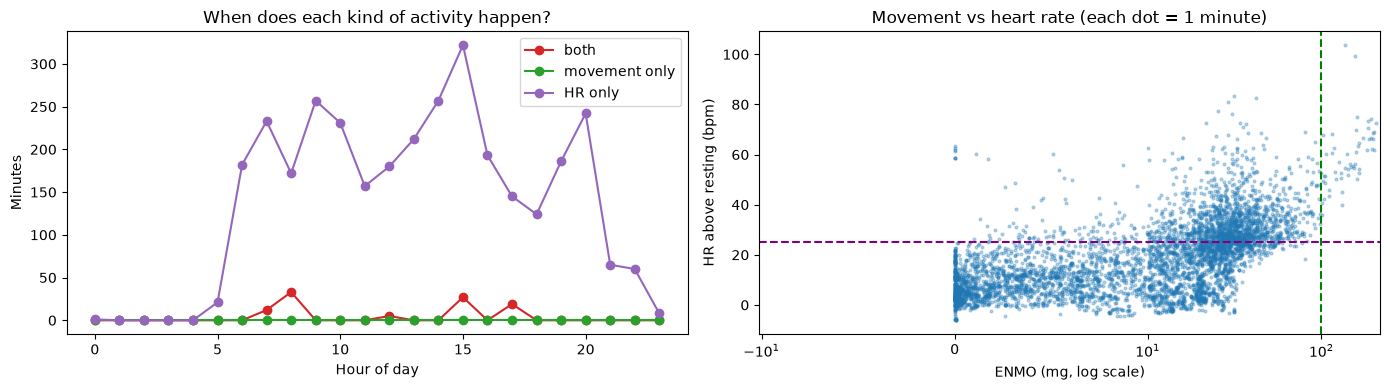

HR-only minutes during detected sleep: 19 (could be sensor noise or dreaming/arousal)


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for t, c in [("both", "tab:red"), ("movement only", "tab:green"), ("HR only", "tab:purple")]:
    s = w[w["activity_type"] == t]
    axes[0].plot(range(24), s.groupby(s.index.hour).size().reindex(range(24), fill_value=0), "o-", color=c, label=t)
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Minutes")
axes[0].set_title("When does each kind of activity happen?")
axes[0].legend()

sample = w.sample(min(len(w), 5000), random_state=0)
axes[1].scatter(sample["enmo_5"], sample["hr_5"] - resting_hr, s=4, alpha=0.3)
axes[1].axvline(ACTIVE_ENMO, color="green", ls="--")
axes[1].axhline(HR_ACTIVE_DELTA, color="purple", ls="--")
axes[1].set_xscale("symlog", linthresh=10)
axes[1].set_xlabel("ENMO (mg, log scale)")
axes[1].set_ylabel("HR above resting (bpm)")
axes[1].set_title("Movement vs heart rate (each dot = 1 minute)")
plt.tight_layout()
plt.show()

print("HR-only minutes during detected sleep:", int(((w["activity_type"] == "HR only") & w["asleep"]).sum()),
      "(could be sensor noise or dreaming/arousal)")

In [10]:
def bouts_of(mask, min_len=BOUT_MIN):
    rid = (mask != mask.shift()).cumsum()
    out = [(s.index[0], s.index[-1], len(s)) for _, s in mask.groupby(rid) if s.iloc[0] and len(s) >= min_len]
    return pd.DataFrame(out, columns=["start", "end", "minutes"])

all_bouts = []
for t in ["both", "movement only", "HR only"]:
    bt = bouts_of(w["activity_type"].eq(t).reindex(wear.index, fill_value=False))
    bt["type"] = t
    all_bouts.append(bt)
all_bouts = pd.concat(all_bouts, ignore_index=True)
print(all_bouts.groupby("type")["minutes"].agg(["count", "median", "sum"]).rename(columns={"count": "bouts"}))

         bouts median   sum
type                       
HR only    102   17.0  2170
both         6   10.5    65


## Q2: Glucose during and after active periods

For each bout we take glucose in the 15 minutes before it starts as the baseline, then measure the change at 30, 60, and 120 minutes, and the lowest point in the 2 hours after. Bouts with a meal in the hour before or during them are flagged, because the meal pushes glucose up while the activity pulls it down.

Comparing the bout types is the interesting part: true exercise (**both**) should lower glucose most, while **HR only** (stress-type) episodes can even raise it, because stress hormones release stored glucose.

In [11]:
rows = []
for _, b in all_bouts.iterrows():
    t = b["start"]
    base = grid[t - pd.Timedelta("15min"): t].median()
    after = grid[t: t + pd.Timedelta("2h")]
    if pd.isna(base) or after.count() < 12:
        continue
    rows.append({
        "type": b["type"], "start": t, "minutes": b["minutes"],
        "meal_nearby": ((meals["time"] >= t - pd.Timedelta("1h")) & (meals["time"] <= b["end"])).any(),
        "change_30": grid.asof(t + pd.Timedelta("30min")) - base,
        "change_60": grid.asof(t + pd.Timedelta("60min")) - base,
        "change_120": grid.asof(t + pd.Timedelta("120min")) - base,
        "lowest_2h": after.min() - base,
        "baseline": base,
    })
bout_glu = pd.DataFrame(rows)
if len(bout_glu):
    print(bout_glu.groupby(["type", "meal_nearby"])[["change_30", "change_60", "change_120", "lowest_2h"]]
          .median().round(1))

                     change_30  change_60  change_120  lowest_2h
type    meal_nearby                                             
HR only False             -1.0        2.0         0.0       -8.0
        True               3.0        6.0         0.0       -9.0
both    False            -14.0       -7.0         1.0      -15.5
        True             -56.5      -46.0       -41.0      -56.5


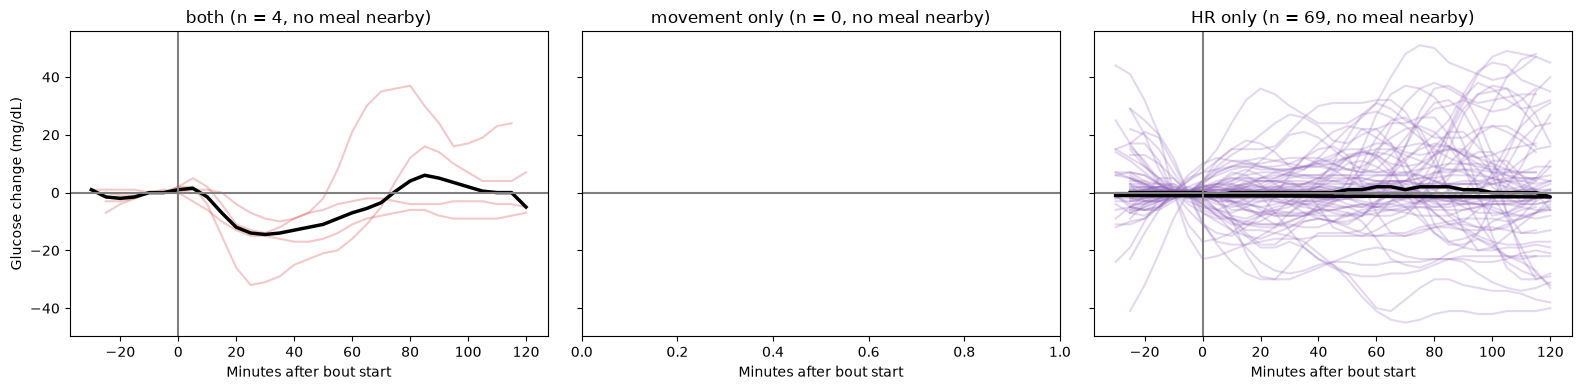

In [12]:
if len(bout_glu):
    colors = {"both": "tab:red", "movement only": "tab:green", "HR only": "tab:purple"}
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    for ax, t in zip(axes, colors):
        sub = bout_glu[(bout_glu["type"] == t) & ~bout_glu["meal_nearby"]]
        curves = []
        for _, r in sub.iterrows():
            seg = grid[r["start"] - pd.Timedelta("30min"): r["start"] + pd.Timedelta("2h")]
            x = np.round((seg.index - r["start"]).total_seconds() / 300) * 5
            ax.plot(x, seg.values - r["baseline"], color=colors[t], alpha=0.25)
            curves.append(pd.Series(seg.values - r["baseline"], index=x))
        if curves:
            med = pd.concat(curves, axis=1).median(axis=1)
            ax.plot(med.index, med.values, color="black", lw=2.5)
        ax.axvline(0, color="gray")
        ax.axhline(0, color="gray")
        ax.set_title(f"{t} (n = {len(sub)}, no meal nearby)")
        ax.set_xlabel("Minutes after bout start")
    axes[0].set_ylabel("Glucose change (mg/dL)")
    plt.tight_layout()
    plt.show()

## Q3 (added): Moving after meals, and active vs inactive days

A short walk after eating is one of the best-studied ways to blunt a glucose spike: working muscles take up glucose without needing as much insulin. We compare meals followed by **at least 15 minutes of light-or-more movement in the hour after eating** with meals that weren't.

We also check at the day level whether more active days have lower or more stable glucose.

In [13]:
mrows = []
for _, m in meals.iterrows():
    t = m["time"]
    pre = grid[t - pd.Timedelta("30min"): t - pd.Timedelta("1s")]
    post = grid[t: t + pd.Timedelta("2h")]
    after = wear.loc[t: t + pd.Timedelta("60min")]
    if pre.count() < 3 or post.count() < 18 or after["worn"].mean() < 0.6:
        continue
    mrows.append({
        "time": t, "foods": str(m["foods"])[:35], "carbs": m["carbs"],
        "rise": post.max() - pre.median(),
        "moving_min_after": int((after["enmo"] >= LIGHT_ENMO).sum()),
    })
mact = pd.DataFrame(mrows)
if len(mact):
    mact["moved_after"] = mact["moving_min_after"] >= 15
    mact["rise_per_10g"] = np.where(mact["carbs"] >= 10, mact["rise"] / mact["carbs"] * 10, np.nan)
    print(mact.groupby("moved_after")[["carbs", "rise", "rise_per_10g"]].median()
          .rename(index={True: "moved after meal", False: "stayed still"}).round(1))
    a = mact.loc[mact["moved_after"], "rise_per_10g"].dropna()
    b2 = mact.loc[~mact["moved_after"], "rise_per_10g"].dropna()
    if len(a) >= 3 and len(b2) >= 3:
        print(f"\nRise per 10 g carbs, moved vs still: Mann–Whitney p = {stats.mannwhitneyu(a, b2).pvalue:.3f}")
mact.round(1)

                  carbs  rise  rise_per_10g
moved_after                                
stayed still       30.3  28.5           7.4
moved after meal   33.0  34.0           9.7

Rise per 10 g carbs, moved vs still: Mann–Whitney p = 0.370


,time,foods,carbs,rise,moving_min_after,moved_after,rise_per_10g
0,2020-02-13 18:00:00,Berry Smoothie,85.0,80.0,9,False,9.4
1,2020-02-13 20:30:00,"Chicken Leg, Asparagus",2.5,-12.5,1,False,NaN
2,2020-02-14 07:10:00,"Natrel Lactose Free 2 Percent, Stan",35.0,27.0,8,False,7.7
3,2020-02-14 09:38:00,Breakfast Trail Mix,30.0,24.0,6,False,8.0
4,2020-02-14 12:38:00,Spinach Salad w/ strawberries and c,14.4,30.0,0,False,20.8
5,2020-02-14 19:30:00,"Acai Smoothie, (Trader Joe's) Mac a",145.5,50.5,1,False,3.5
6,2020-02-15 11:02:00,Breakfast Trail Mix,30.0,15.5,15,True,5.2
7,2020-02-15 12:38:00,"Spinach Salad w/ blueberries, egg,",14.4,9.0,20,True,6.2
8,2020-02-15 15:30:00,"Babel Cheese, Breakfast Trail Mix",30.3,38.0,10,False,12.5
9,2020-02-16 21:10:00,Chai Tea,3.4,28.5,0,False,NaN


In [14]:
day = df[df["worn"]].groupby("date").agg(
    readings=("glucose", "count"), mean_glucose=("glucose", "mean"), sd_glucose=("glucose", "std"))
day["active_min"] = wear.loc[wear["worn"], "enmo"].ge(ACTIVE_ENMO).groupby(wear.loc[wear["worn"]].index.date).sum()
day = day[day["readings"] >= 230]
for y in ["mean_glucose", "sd_glucose"]:
    if len(day) >= 5:
        rho, p = stats.spearmanr(day["active_min"], day[y])
        print(f"Active minutes vs {y}: rho = {rho:+.2f} (p = {p:.3f}, n = {len(day)} days)")
day.round(1)

,readings,mean_glucose,sd_glucose,active_min
date,,,,
2020-02-14,287,100.0,15.6,5
2020-02-17,278,101.1,15.6,30
2020-02-18,285,111.3,12.4,5
2020-02-20,255,110.0,15.3,22


---
# Part B: Sleep

## Q4: Sleep from movement and heart rate, and glucose stability

Stage 7 detected sleep from stillness alone. Lying still while awake (reading, watching TV) fools that method. Heart rate helps: it drops during real sleep. Here a minute is sleep-like only if, between 21:00 and 11:00:
- the 30-min ENMO is below `SLEEP_ENMO`, **and**
- the 30-min HR is below the participant's typical night-time HR + 5 bpm

We then compare glucose **stability** asleep vs awake using SD, CV, the average speed of change, and the % of time glucose is steady (changing by less than 1 mg/dL/min).

In [15]:
def fill_short_gaps(b, max_gap):
    b = b.astype(bool).copy()
    rid = (b != b.shift()).cumsum()
    for _, seg in b.groupby(rid):
        if not seg.iloc[0] and len(seg) <= max_gap and seg.index[0] != b.index[0] and seg.index[-1] != b.index[-1]:
            b.loc[seg.index] = True
    return b

def true_runs(b):
    rid = (b != b.shift()).cumsum()
    return [(s.index[0], s.index[-1], len(s)) for _, s in b.groupby(rid) if s.iloc[0]]

hour = wear.index.hour
night_hours = (hour >= 21) | (hour < 11)
night_hr = wear.loc[wear["worn"] & (hour < 5), "hr"].median()
sleep_like = (wear["enmo_30"] < SLEEP_ENMO) & (wear["hr_30"] < night_hr + 5) & night_hours & wear["worn"]

wear["asleep2"] = False
nights = []
for n, s in sleep_like.groupby((wear.index - pd.Timedelta("12h")).date):
    runs = true_runs(fill_short_gaps(s, 15))
    if not runs:
        continue
    on, off, length = max(runs, key=lambda r: r[2])
    if length < 120:
        continue
    wear.loc[on:off, "asleep2"] = True
    seg = wear.loc[on:off]
    nights.append({"night_of": n, "onset": on, "wake": off, "hours": length / 60,
                   "restless_%": (seg["enmo"] > 20).mean() * 100,
                   "sleep_hr": seg["hr"].mean(), "sleep_temp": seg["temp"].mean()})
nights = pd.DataFrame(nights).set_index("night_of") if nights else pd.DataFrame()

both = wear["worn"]
agree = (wear.loc[both, "asleep"] == wear.loc[both, "asleep2"]).mean() * 100
print(f"Night-time HR reference: {night_hr:.0f} bpm")
print(f"Nights detected: {len(nights)} | agreement with Stage 7 (movement only): {agree:.1f}% of minutes")
print(f"Minutes Stage 7 called sleep but HR says awake: {int((wear['asleep'] & ~wear['asleep2']).sum())}")
nights.assign(onset=lambda d: d["onset"].dt.strftime("%H:%M"), wake=lambda d: d["wake"].dt.strftime("%H:%M")).round(1) \
    if len(nights) else "No nights detected"

Night-time HR reference: 59 bpm
Nights detected: 7 | agreement with Stage 7 (movement only): 90.1% of minutes
Minutes Stage 7 called sleep but HR says awake: 701


,onset,wake,hours,restless_%,sleep_hr,sleep_temp
night_of,,,,,,
2020-02-13,03:54,06:04,2.2,10.7,59.6,35.8
2020-02-14,02:44,06:13,3.5,5.2,57.9,35.9
2020-02-16,01:26,05:39,4.2,2.4,57.6,36.0
2020-02-17,02:04,05:31,3.5,7.7,57.0,36.0
2020-02-18,04:51,07:15,2.4,0.0,58.6,36.3
2020-02-19,22:48,02:06,3.3,1.5,58.5,35.6
2020-02-21,02:48,06:17,3.5,4.3,57.4,36.0


In [16]:
df["asleep2"] = wear["asleep2"].reindex(df.index.floor("min")).fillna(False).astype(bool).values
rate = df["glucose"].diff() / 5

def stability(mask):
    g, r = df.loc[mask, "glucose"], rate[mask]
    return pd.Series({"readings": g.count(), "mean": g.mean(), "SD": g.std(), "CV %": g.std() / g.mean() * 100,
                      "mean |rate|": r.abs().mean(), "% steady": (r.abs() < 1).mean() * 100})

stab = pd.DataFrame({
    "asleep": stability(df["asleep2"]),
    "awake, resting": stability(~df["asleep2"] & (df["state"] == "rest")),
    "awake, all": stability(~df["asleep2"] & df["worn"]),
}).round(2)
stab

,asleep,"awake, resting","awake, all"
readings,242.00,1651.00,1808.00
mean,99.35,106.93,107.68
SD,10.82,16.48,16.64
CV %,10.89,15.41,15.45
mean |rate|,0.27,0.44,0.44
% steady,84.87,86.38,86.62


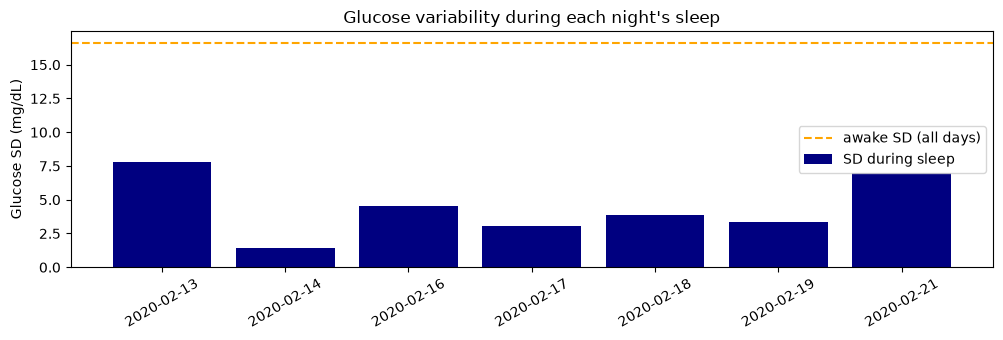

In [17]:
if len(nights):
    per_night = []
    for n, r in nights.iterrows():
        g = grid[r["onset"]:r["wake"]]
        per_night.append({"night_of": n, "sleep mean": g.mean(), "sleep SD": g.std(),
                          "sleep |rate|": (g.diff() / 5).abs().mean()})
    per_night = pd.DataFrame(per_night).set_index("night_of")
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.bar([str(d) for d in per_night.index], per_night["sleep SD"], color="navy", label="SD during sleep")
    ax.axhline(stab.loc["SD", "awake, all"], color="orange", ls="--", label="awake SD (all days)")
    ax.set_ylabel("Glucose SD (mg/dL)")
    ax.set_title("Glucose variability during each night's sleep")
    ax.legend()
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

## Q5 (added): Sleep and next-day glucose

Short or disturbed sleep is known to reduce insulin sensitivity the next day in experimental studies. With ~8 nights we can't prove anything, but we can look for hints. For each night we compare sleep **duration**, **onset time**, **restlessness**, and **sleep HR** with:
- **wake glucose**: median glucose in the 30 min after waking (before most breakfasts)
- **next-day mean and SD** of glucose (wake to 22:00)

In [18]:
if len(nights):
    nd = nights.copy()
    nd["onset_hour"] = (nd["onset"].dt.hour + nd["onset"].dt.minute / 60 + 12) % 24 - 12   # 23:00 → -1
    nd["wake_glucose"] = [grid[r["wake"]: r["wake"] + pd.Timedelta("30min")].median() for _, r in nd.iterrows()]
    nd["next_day_mean"] = [grid[r["wake"]: r["wake"].normalize() + pd.Timedelta("22h")].mean() for _, r in nd.iterrows()]
    nd["next_day_SD"] = [grid[r["wake"]: r["wake"].normalize() + pd.Timedelta("22h")].std() for _, r in nd.iterrows()]

    res = {}
    for x in ["hours", "onset_hour", "restless_%", "sleep_hr"]:
        for y in ["wake_glucose", "next_day_mean", "next_day_SD"]:
            d = nd[[x, y]].dropna()
            if len(d) >= 5:
                rho, p = stats.spearmanr(d[x], d[y])
                res[(x, y)] = {"rho": rho, "p": p, "n": len(d)}
    print(pd.DataFrame(res).T.round(2) if res else "Not enough nights")

                           rho     p    n
hours      wake_glucose   0.00  1.00  6.0
           next_day_mean -0.52  0.23  7.0
           next_day_SD   -0.50  0.25  7.0
onset_hour wake_glucose   0.26  0.62  6.0
           next_day_mean  0.21  0.64  7.0
           next_day_SD    0.54  0.22  7.0
restless_% wake_glucose  -0.49  0.33  6.0
           next_day_mean -0.39  0.38  7.0
           next_day_SD    0.00  1.00  7.0
sleep_hr   wake_glucose  -0.43  0.40  6.0
           next_day_mean  0.00  1.00  7.0
           next_day_SD    0.25  0.59  7.0


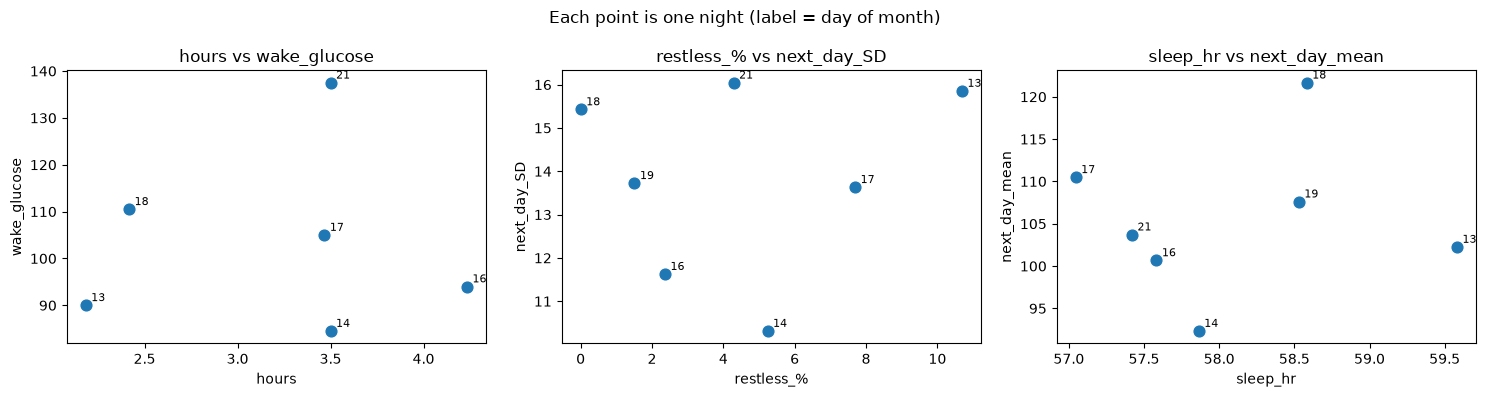

In [19]:
if len(nights):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (x, y) in zip(axes, [("hours", "wake_glucose"), ("restless_%", "next_day_SD"), ("sleep_hr", "next_day_mean")]):
        ax.scatter(nd[x], nd[y], s=60)
        for n, r in nd.iterrows():
            ax.annotate(f"{n:%d}", (r[x], r[y]), textcoords="offset points", xytext=(4, 3), fontsize=8)
        ax.set_xlabel(x)
        ax.set_ylabel(y)
        ax.set_title(f"{x} vs {y}")
    plt.suptitle("Each point is one night (label = day of month)")
    plt.tight_layout()
    plt.show()

---
# Part C: Heart rate and glucose

## Q6 (added): The HR–glucose correlation, done properly

Your first attempt (at the very start of this project) found r ≈ −0.07 across all data. That single number mixes together very different situations. A careful analysis asks several questions:

1. **By state:** is the relationship different during sleep, rest, and activity?
2. **Detrended:** do *changes* in HR go with *changes* in glucose? Using 5-minute differences removes slow shared trends such as the daily rhythm.
3. **Adjusted (partial correlation):** what is left after removing the effects of movement and time of day from both signals?
4. **Within each day:** is the relationship consistent from day to day, or driven by one day?
5. **Lagged:** does one signal lead the other?

There's also a statistics trap: neighbouring 5-minute readings are nearly identical, so the **effective sample size** is far smaller than the number of rows. We correct the p-value for this.

In [20]:
def effective_n(x, y):
    """Approximate number of independent samples, given lag-1 autocorrelation in both series."""
    r1x = pd.Series(x).autocorr(1)
    r1y = pd.Series(y).autocorr(1)
    return max(3, len(x) * (1 - r1x * r1y) / (1 + r1x * r1y))

def corr_report(x, y):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(d) < 10:
        return pd.Series({"n": len(d)})
    r, p = stats.pearsonr(d["x"], d["y"])
    rho, _ = stats.spearmanr(d["x"], d["y"])
    n_eff = effective_n(d["x"].values, d["y"].values)
    t = r * np.sqrt((n_eff - 2) / max(1e-9, 1 - r ** 2))
    p_eff = 2 * stats.t.sf(abs(t), n_eff - 2)
    return pd.Series({"n": len(d), "pearson r": r, "spearman rho": rho, "p (naive)": p,
                      "effective n": n_eff, "p (corrected)": p_eff})

d = df[df["worn"]]
report = {"all worn data": corr_report(d["glucose"], d["hr"])}
for s in ["sleep", "rest", "active"]:
    sub = d[d["state"] == s]
    report[f"state: {s}"] = corr_report(sub["glucose"], sub["hr"])

# Differences (only where consecutive slots both exist)
dg, dh = df["glucose"].diff(), df["hr"].diff()
report["5-min changes"] = corr_report(dg[df["worn"]], dh[df["worn"]])

# Partial correlation: remove movement and time of day from both
pc = d[["glucose", "hr", "enmo_30", "hour_sin", "hour_cos"]].dropna()
X = np.column_stack([np.ones(len(pc)), pc[["enmo_30", "hour_sin", "hour_cos"]].values])
res_g = pc["glucose"] - X @ np.linalg.lstsq(X, pc["glucose"], rcond=None)[0]
res_h = pc["hr"] - X @ np.linalg.lstsq(X, pc["hr"], rcond=None)[0]
report["adjusted for movement + time of day"] = corr_report(res_g, res_h)

pd.DataFrame(report).T.round(3)

,n,pearson r,spearman rho,p (naive),effective n,p (corrected)
all worn data,2049.0,-0.070,-0.083,0.001,321.468,0.210
state: sleep,308.0,0.543,0.502,0.000,48.428,0.000
state: rest,1721.0,-0.154,-0.209,0.000,338.006,0.005
state: active,20.0,-0.466,-0.363,0.038,20.928,0.033
5-min changes,2040.0,-0.010,-0.011,0.667,2925.364,0.606
adjusted for movement + time of day,2032.0,0.090,0.079,0.000,527.087,0.040


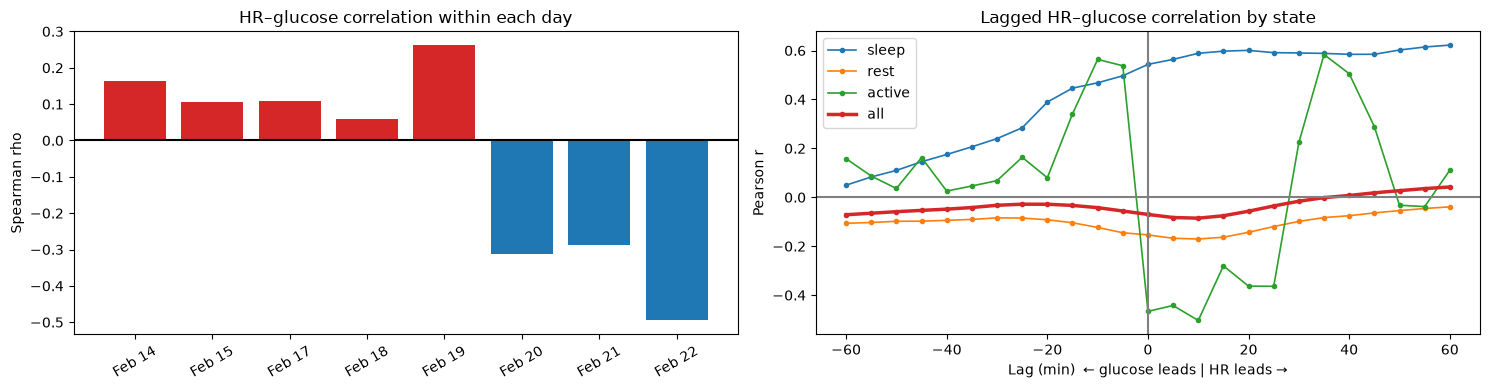

Days with positive / negative correlation: 5 / 3


In [21]:
within = []
for dte, sub in d.groupby("date"):
    s = sub[["glucose", "hr"]].dropna()
    if len(s) >= 150:
        within.append({"date": dte, "rho": stats.spearmanr(s["glucose"], s["hr"])[0], "n": len(s)})
within = pd.DataFrame(within)

lags = range(-12, 13)
lag_tab = pd.DataFrame({
    s: [d.loc[d["state"] == s, "glucose"].corr(df["hr"].shift(l).reindex(d.index)[d["state"] == s]) for l in lags]
    for s in ["sleep", "rest", "active"]
}, index=[l * 5 for l in lags])
lag_tab["all"] = [d["glucose"].corr(df["hr"].shift(l).reindex(d.index)) for l in lags]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
if len(within):
    axes[0].bar([f"{x:%b %d}" for x in within["date"]], within["rho"], color=np.where(within["rho"] > 0, "tab:red", "tab:blue"))
    axes[0].axhline(0, color="black")
    axes[0].set_title("HR–glucose correlation within each day")
    axes[0].set_ylabel("Spearman rho")
    axes[0].tick_params(axis="x", rotation=30)
for c in lag_tab:
    axes[1].plot(lag_tab.index, lag_tab[c], "o-", ms=3, label=c, lw=2.5 if c == "all" else 1.2)
axes[1].axvline(0, color="gray")
axes[1].axhline(0, color="gray")
axes[1].set_xlabel("Lag (min)  ← glucose leads | HR leads →")
axes[1].set_ylabel("Pearson r")
axes[1].set_title("Lagged HR–glucose correlation by state")
axes[1].legend()
plt.tight_layout()
plt.show()
if len(within):
    print(f"Days with positive / negative correlation: {(within['rho'] > 0).sum()} / {(within['rho'] < 0).sum()}")

## Q7 (added): Does heart rate rise after meals?

Digesting food takes energy and shifts blood flow to the gut, so heart rate often rises by a few beats per minute after eating, even when sitting still. This is one real, direct link between eating, glucose, and HR.

We compare HR in the 30 minutes **before** each meal with HR **30–90 minutes after**, keeping only meals where the participant was resting in both windows (mean ENMO below the light-activity threshold), so movement doesn't explain the change.

In [22]:
pp = []
for _, m in meals.iterrows():
    t = m["time"]
    pre = wear.loc[t - pd.Timedelta("30min"): t]
    post = wear.loc[t + pd.Timedelta("30min"): t + pd.Timedelta("90min")]
    if pre["hr"].count() < 20 or post["hr"].count() < 40:
        continue
    if pre["enmo"].mean() >= LIGHT_ENMO or post["enmo"].mean() >= LIGHT_ENMO:
        continue
    pp.append({"time": t, "foods": str(m["foods"])[:35], "carbs": m["carbs"], "calories": m["calories"],
               "hr_before": pre["hr"].mean(), "hr_after": post["hr"].mean()})
pp = pd.DataFrame(pp)
if len(pp):
    pp["hr_change"] = pp["hr_after"] - pp["hr_before"]
    print(f"Resting meals: {len(pp)} | median HR change: {pp['hr_change'].median():+.1f} bpm")
    if len(pp) >= 5:
        print(f"Wilcoxon test (change ≠ 0): p = {stats.wilcoxon(pp['hr_change']).pvalue:.3f}")
        for x in ["carbs", "calories"]:
            dd = pp[[x, "hr_change"]].dropna()
            if len(dd) >= 5:
                rho, p = stats.spearmanr(dd[x], dd["hr_change"])
                print(f"{x} vs HR change: rho = {rho:+.2f} (p = {p:.3f})")
pp.round(1) if len(pp) else "No meals eaten at rest with enough HR data before and after"

Resting meals: 22 | median HR change: -1.7 bpm
Wilcoxon test (change ≠ 0): p = 0.262
carbs vs HR change: rho = +0.29 (p = 0.187)
calories vs HR change: rho = -0.18 (p = 0.424)


,time,foods,carbs,calories,hr_before,hr_after,hr_change
0,2020-02-13 18:00:00,Berry Smoothie,85.0,456.0,77.2,79.2,2.0
1,2020-02-13 20:30:00,"Chicken Leg, Asparagus",2.5,488.0,82.5,69.7,-12.8
2,2020-02-14 09:38:00,Breakfast Trail Mix,30.0,280.0,85.0,89.6,4.5
3,2020-02-14 12:38:00,Spinach Salad w/ strawberries and c,14.4,358.0,76.6,73.6,-3.0
4,2020-02-14 19:30:00,"Acai Smoothie, (Trader Joe's) Mac a",145.5,892.0,82.2,81.7,-0.4
5,2020-02-15 11:02:00,Breakfast Trail Mix,30.0,280.0,84.7,82.3,-2.4
6,2020-02-15 12:38:00,"Spinach Salad w/ blueberries, egg,",14.4,358.0,85.3,88.1,2.8
7,2020-02-16 21:10:00,Chai Tea,3.4,12.0,74.2,67.5,-6.7
8,2020-02-17 12:30:00,"Chicken Nuggets, Salad with Cranber",28.2,227.0,81.4,80.5,-1.0
9,2020-02-17 21:00:00,"Kale Salad, Pizza",40.0,368.7,81.6,75.6,-6.0


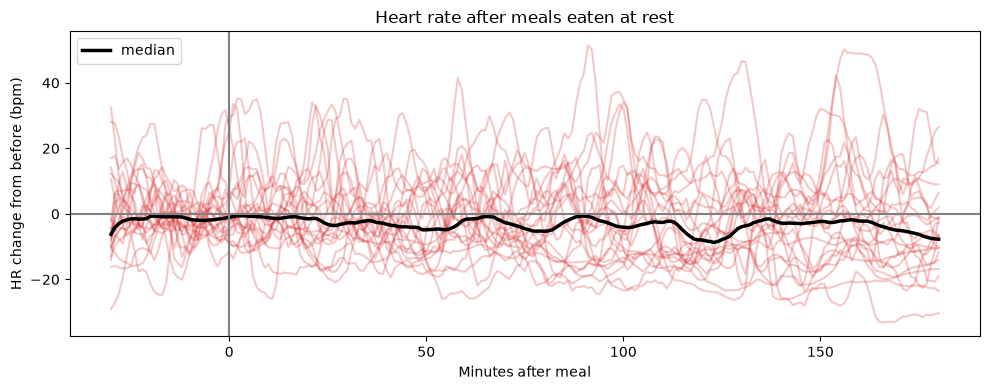

In [23]:
if len(pp):
    fig, ax = plt.subplots(figsize=(10, 4))
    curves = []
    for _, r in pp.iterrows():
        seg = wear.loc[r["time"] - pd.Timedelta("30min"): r["time"] + pd.Timedelta("3h"), "hr"].rolling(5, min_periods=1).mean()
        x = (seg.index - r["time"]).total_seconds() / 60
        ax.plot(x, seg.values - r["hr_before"], color="tab:red", alpha=0.25)
        curves.append(pd.Series(seg.values - r["hr_before"], index=np.round(x)))
    med = pd.concat(curves, axis=1).median(axis=1).rolling(10, min_periods=1).mean()
    ax.plot(med.index, med.values, color="black", lw=2.5, label="median")
    ax.axvline(0, color="gray")
    ax.axhline(0, color="gray")
    ax.set_xlabel("Minutes after meal")
    ax.set_ylabel("HR change from before (bpm)")
    ax.set_title("Heart rate after meals eaten at rest")
    ax.legend()
    plt.tight_layout()
    plt.show()

---
# Part D: The other sensors

## Q8 (added): Heart rate variability (HRV)

HRV is one of the richest signals in this dataset. Things to expect:
- RMSSD is **higher during sleep** (rest-and-digest dominates)
- RMSSD often **drops after a large meal** (digestion shifts the nervous-system balance)
- Lower HRV has been linked to poorer glucose regulation in population studies, but within one person over 9 days the link may be weak

Wrist HRV is noisy, especially during movement, so we report how much usable data there is first.

In [24]:
worn_windows = df["worn"].groupby(df.index.floor("5min")).any().sum()
print(f"5-min windows with usable HRV: {df['rmssd'].notna().groupby(df.index.floor('5min')).any().sum()} "
      f"of {worn_windows} worn windows")

hrv_state = df.groupby("state")["rmssd"].agg(["count", "median", "mean"]).round(1)
print("\nRMSSD (ms) by state:")
print(hrv_state)

for label, sub in [("all", df), ("asleep", df[df["asleep2"]]), ("awake rest", df[df["state"] == "rest"])]:
    r = sub[["rmssd", "glucose"]].dropna()
    if len(r) >= 20:
        rho, p = stats.spearmanr(r["rmssd"], r["glucose"])
        print(f"RMSSD vs glucose ({label}): rho = {rho:+.2f} (n = {len(r)})")

5-min windows with usable HRV: 1307 of 2087 worn windows

RMSSD (ms) by state:
          count  median  mean
state                        
active        5    58.9  65.5
not worn      7    43.0  45.1
rest        966    65.5  64.5
sleep       329    57.2  56.7
RMSSD vs glucose (all): rho = -0.06 (n = 1270)
RMSSD vs glucose (asleep): rho = -0.18 (n = 233)
RMSSD vs glucose (awake rest): rho = -0.03 (n = 958)


Meals with HRV before and after: 14 | median RMSSD change: -2.1 ms


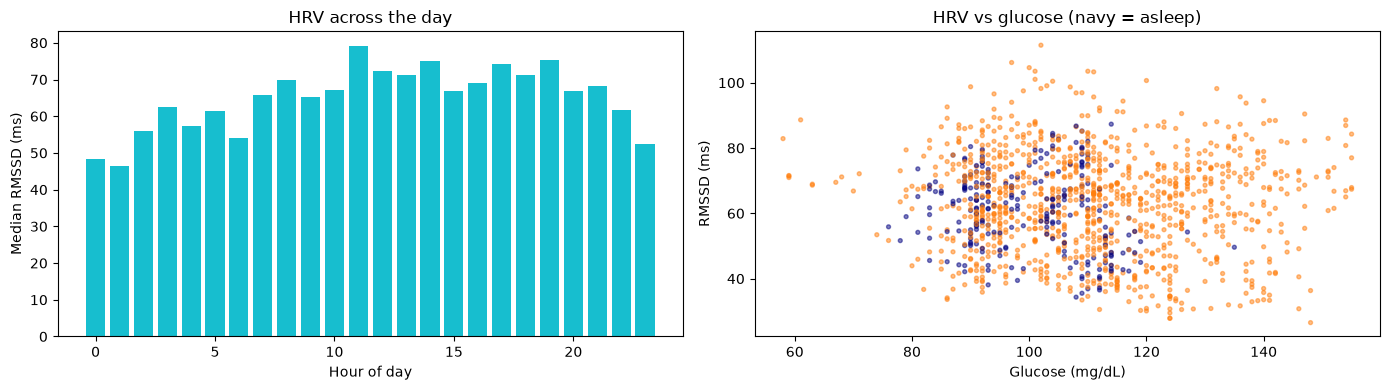

In [25]:
hp = []
for _, m in meals.iterrows():
    t = m["time"]
    pre = df.loc[t - pd.Timedelta("30min"): t, "rmssd"]
    post = df.loc[t + pd.Timedelta("30min"): t + pd.Timedelta("90min"), "rmssd"]
    if pre.count() >= 2 and post.count() >= 4:
        hp.append({"time": t, "carbs": m["carbs"], "rmssd_before": pre.median(), "rmssd_after": post.median()})
hp = pd.DataFrame(hp)
if len(hp):
    hp["change"] = hp["rmssd_after"] - hp["rmssd_before"]
    print(f"Meals with HRV before and after: {len(hp)} | median RMSSD change: {hp['change'].median():+.1f} ms")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hourly_hrv = df.groupby(df.index.hour)["rmssd"].median()
axes[0].bar(hourly_hrv.index, hourly_hrv.values, color="tab:cyan")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Median RMSSD (ms)")
axes[0].set_title("HRV across the day")
s = df[["rmssd", "glucose", "asleep2"]].dropna()
axes[1].scatter(s["glucose"], s["rmssd"], c=np.where(s["asleep2"], "navy", "tab:orange"), s=8, alpha=0.5)
axes[1].set_xlabel("Glucose (mg/dL)")
axes[1].set_ylabel("RMSSD (ms)")
axes[1].set_title("HRV vs glucose (navy = asleep)")
plt.tight_layout()
plt.show()

## Q9 (added): Electrodermal activity (EDA) and stress-like moments

EDA measures how well the skin conducts electricity, which rises when sweat glands are activated by the **sympathetic** ("fight-or-flight") nervous system. Two parts matter:
- **tonic level (SCL)**: the slow baseline, in microsiemens (µS)
- **phasic responses (SCRs)**: short bursts, counted per 30 min here

Stress hormones such as adrenaline and cortisol can raise glucose, so we look for **arousal without movement**: awake, still, but with a burst of SCRs. Then we check what glucose does in the hour after.

One surprising pattern: many people show "EDA storms" (lots of SCRs) during deep sleep. That is normal and not stress.

In [26]:
if df["eda"].notna().any():
    print("EDA (µS) and SCRs per 30 min by state:")
    print(df.groupby("state")[["eda", "scr_30"]].median().round(3))

    still_awake = (df["state"] == "rest") & df["scr_30"].notna()
    thr = df.loc[still_awake, "scr_30"].quantile(0.9)
    arousal = still_awake & (df["scr_30"] >= max(thr, 1))
    rid = (arousal != arousal.shift()).cumsum()
    episodes = [(s.index[0], len(s)) for _, s in arousal.groupby(rid) if s.iloc[0] and len(s) >= 2]
    ep_rows = []
    for t, n in episodes:
        base = grid[t - pd.Timedelta("15min"): t].median()
        if pd.isna(base):
            continue
        meal_near = ((meals["time"] >= t - pd.Timedelta("2h")) & (meals["time"] <= t + pd.Timedelta("1h"))).any()
        ep_rows.append({"start": t, "length_min": n * 5, "meal_nearby": meal_near,
                        "glucose_change_60": grid.asof(t + pd.Timedelta("60min")) - base})
    eda_ep = pd.DataFrame(ep_rows)
    print(f"\nArousal-without-movement episodes: {len(eda_ep)} (SCR threshold {max(thr, 1):.0f} per 30 min)")
    if len(eda_ep):
        print(eda_ep.groupby("meal_nearby")["glucose_change_60"].median().rename("median glucose change in 60 min").round(1))
else:
    eda_ep = pd.DataFrame()
    print("No EDA data")

EDA (µS) and SCRs per 30 min by state:
            eda  scr_30
state                  
active    0.894   124.5
not worn  0.269    59.5
rest      0.214    57.0
sleep     0.794    57.0

Arousal-without-movement episodes: 28 (SCR threshold 239 per 30 min)
meal_nearby
False     1.5
True     15.8
Name: median glucose change in 60 min, dtype: float64


EDA level vs glucose (rest): rho = -0.01
EDA level vs glucose (sleep): rho = +0.03


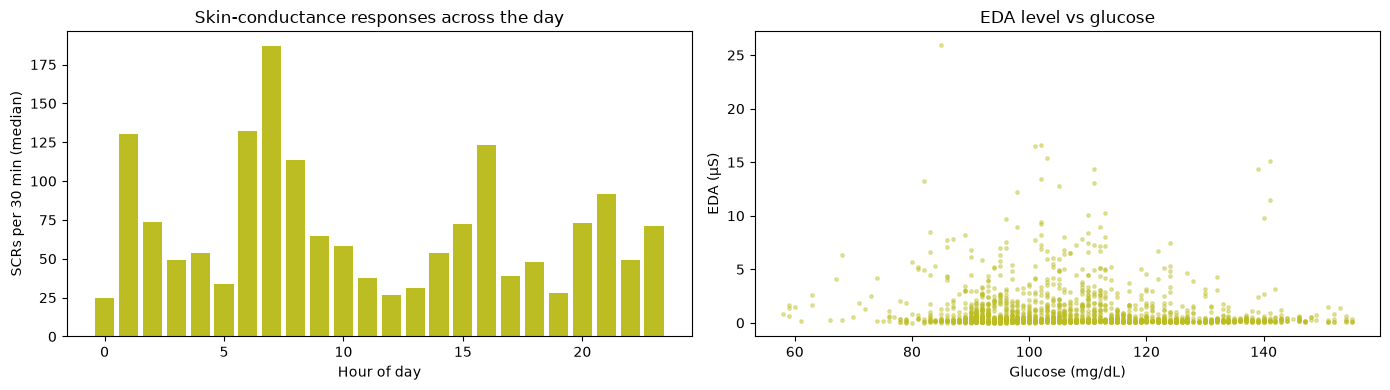

In [27]:
if df["eda"].notna().any():
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    hourly_eda = df.groupby(df.index.hour)[["eda", "scr_30"]].median()
    axes[0].bar(hourly_eda.index, hourly_eda["scr_30"], color="tab:olive")
    axes[0].set_xlabel("Hour of day")
    axes[0].set_ylabel("SCRs per 30 min (median)")
    axes[0].set_title("Skin-conductance responses across the day")
    for label, sub in [("rest", df[df["state"] == "rest"]), ("sleep", df[df["state"] == "sleep"])]:
        r = sub[["eda", "glucose"]].dropna()
        if len(r) >= 20:
            print(f"EDA level vs glucose ({label}): rho = {stats.spearmanr(r['eda'], r['glucose'])[0]:+.2f}")
    s = df[["eda", "glucose"]].dropna()
    axes[1].scatter(s["glucose"], s["eda"], s=6, alpha=0.4, color="tab:olive")
    axes[1].set_xlabel("Glucose (mg/dL)")
    axes[1].set_ylabel("EDA (µS)")
    axes[1].set_title("EDA level vs glucose")
    plt.tight_layout()
    plt.show()

## Q10 (added): Skin temperature

Wrist temperature follows a strong daily rhythm: it **rises when we fall asleep**, because blood vessels in the hands and wrists open to release heat. That makes it a useful extra sleep marker. After a meal, skin temperature can rise slightly too (diet-induced heat production).

We look at the daily pattern, sleep vs awake, the change after meals at rest, and the overall link with glucose.

          count  median
state                  
active       20   31.99
not worn      8   35.39
rest       1660   33.20
sleep       337   36.01

Median temperature change at sleep onset: +0.24 °C
Median skin-temperature change after meals at rest: +0.24 °C (n = 22)
Skin temperature vs glucose: rho = +0.23


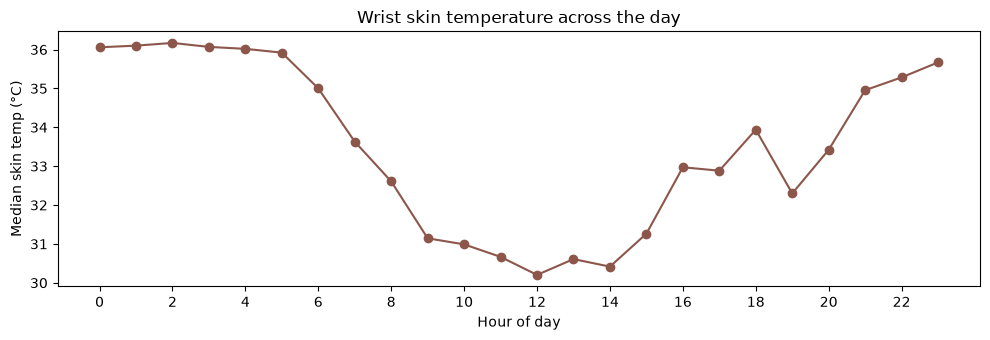

In [28]:
if df["temp"].notna().any():
    print(df.groupby("state")["temp"].agg(["count", "median"]).round(2))
    if len(nights):
        on_rise = []
        for _, r in nights.iterrows():
            before = wear.loc[r["onset"] - pd.Timedelta("1h"): r["onset"], "temp"].mean()
            after = wear.loc[r["onset"] + pd.Timedelta("30min"): r["onset"] + pd.Timedelta("90min"), "temp"].mean()
            on_rise.append(after - before)
        print(f"\nMedian temperature change at sleep onset: {np.nanmedian(on_rise):+.2f} °C")

    tp = []
    for _, m in meals.iterrows():
        t = m["time"]
        pre = wear.loc[t - pd.Timedelta("30min"): t]
        post = wear.loc[t + pd.Timedelta("30min"): t + pd.Timedelta("90min")]
        if pre["temp"].count() >= 20 and post["temp"].count() >= 40 and post["enmo"].mean() < LIGHT_ENMO:
            tp.append(post["temp"].mean() - pre["temp"].mean())
    if tp:
        print(f"Median skin-temperature change after meals at rest: {np.median(tp):+.2f} °C (n = {len(tp)})")

    r = df[["temp", "glucose"]].dropna()
    print(f"Skin temperature vs glucose: rho = {stats.spearmanr(r['temp'], r['glucose'])[0]:+.2f}")

    fig, ax = plt.subplots(figsize=(10, 3.5))
    ht = df.groupby(df.index.hour)["temp"].median()
    ax.plot(ht.index, ht.values, "o-", color="tab:brown")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Median skin temp (°C)")
    ax.set_title("Wrist skin temperature across the day")
    ax.set_xticks(range(0, 24, 2))
    plt.tight_layout()
    plt.show()
else:
    print("No temperature data")

---
# Part E: Putting it all together

## Q11 (added): Which wearable features move most with glucose?

We correlate every feature with two targets:
- **glucose now**
- **glucose change over the next 30 minutes**: can any signal *anticipate* a rise or fall?

The heatmap also shows how the features relate to **each other**. Strongly related features (e.g. HR and movement) carry overlapping information, which matters for the model in Q12.

In [29]:
FEATURES = ["hr", "hr_30", "enmo", "enmo_30", "eda", "scr_30", "temp", "rmssd",
            "hour_sin", "hour_cos", "min_since_meal", "carbs_2h"]
FEATURES = [f for f in FEATURES if df[f].notna().sum() > 50]
df["glucose_next30"] = df["glucose"].shift(-6) - df["glucose"]

cw = df[df["worn"]]
rank_tab = pd.DataFrame({
    "rho with glucose": [cw[[f, "glucose"]].dropna().corr("spearman").iloc[0, 1] for f in FEATURES],
    "rho with next-30-min change": [cw[[f, "glucose_next30"]].dropna().corr("spearman").iloc[0, 1] for f in FEATURES],
    "data available %": [cw[f].notna().mean() * 100 for f in FEATURES],
}, index=FEATURES).round(3)
rank_tab.sort_values("rho with glucose", key=abs, ascending=False)

,rho with glucose,rho with next-30-min change,data available %
min_since_meal,-0.294,-0.055,99.617
carbs_2h,0.262,0.100,100.000
enmo_30,-0.241,0.137,99.138
hour_cos,0.241,-0.089,100.000
temp,0.234,-0.135,96.646
hour_sin,-0.219,-0.052,100.000
enmo,-0.186,0.054,99.952
scr_30,-0.133,0.030,98.946
hr_30,-0.101,0.149,99.090
hr,-0.083,0.109,99.952


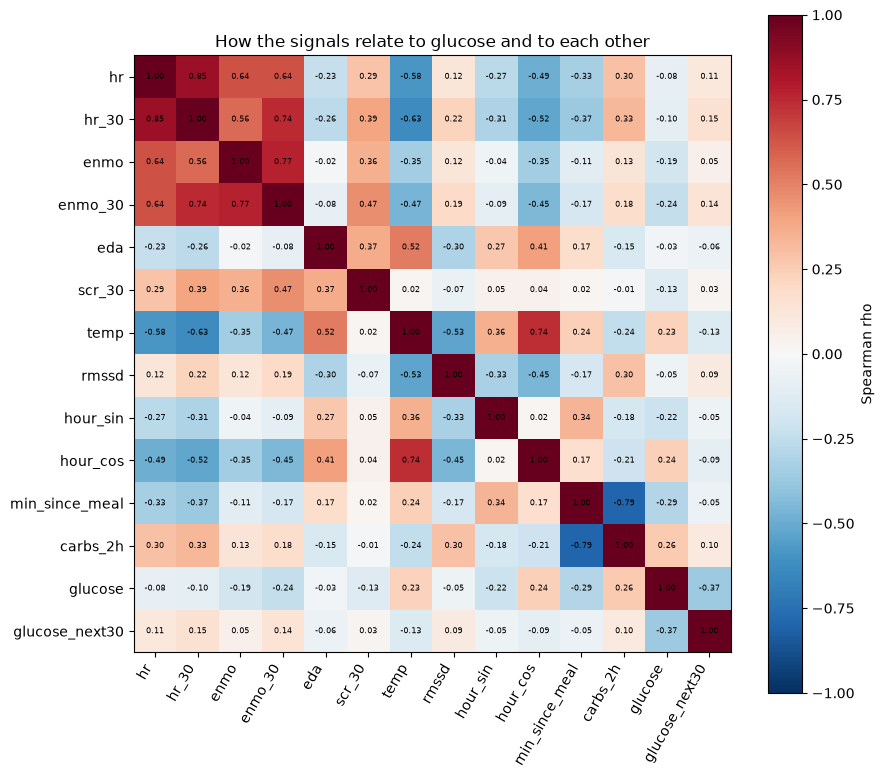

In [30]:
cm = cw[FEATURES + ["glucose", "glucose_next30"]].corr("spearman")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm)))
ax.set_xticklabels(cm.columns, rotation=60, ha="right")
ax.set_yticks(range(len(cm)))
ax.set_yticklabels(cm.index)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, ax=ax, label="Spearman rho")
ax.set_title("How the signals relate to glucose and to each other")
plt.tight_layout()
plt.show()

## Q12 (added): Can wearables estimate glucose without a CGM?

This is the central question of the original study behind this dataset: can a smartwatch act as a "digital biomarker" of glucose?

We train models to estimate **current glucose** from wearable and food-log features only (no past glucose values), and test them with **leave-one-day-out** validation: train on all days but one, predict the held-out day, and repeat. Testing on a day the model never saw is essential, because neighbouring 5-minute rows are almost identical. A random train/test split would let the model "cheat" by memorising its neighbours.

Every model is compared with two baselines that use no sensors at all:
- **overall mean**: always predict the training-days average
- **time-of-day mean**: predict the training-days average for that hour

If a model can't beat the time-of-day baseline, the sensors add nothing beyond the daily routine.

*Requires `scikit-learn` (`pip install scikit-learn`).*

In [31]:
try:
    from sklearn.linear_model import Ridge
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    SKLEARN = True
except ImportError:
    SKLEARN = False
    print("scikit-learn not installed: run `pip install scikit-learn` to use Q12")

WEARABLE = [f for f in ["hr", "hr_30", "enmo", "enmo_30", "eda", "scr_30", "temp", "hour_sin", "hour_cos"] if f in FEATURES]
WITH_FOOD = WEARABLE + [f for f in ["min_since_meal", "carbs_2h"] if f in FEATURES]

model_df = df[df["worn"]].dropna(subset=["glucose"] + WITH_FOOD).copy()
model_df["min_since_meal"] = model_df["min_since_meal"].clip(upper=600)
full_days = model_df.groupby("date").size()
test_days = list(full_days[full_days >= 150].index)
print(f"Rows: {len(model_df)} | days usable for testing: {len(test_days)}")
print("Wearable features:", WEARABLE)

Rows: 1951 | days usable for testing: 8
Wearable features: ['hr', 'hr_30', 'enmo', 'enmo_30', 'eda', 'scr_30', 'temp', 'hour_sin', 'hour_cos']


In [32]:
def metrics(y, p):
    e = np.asarray(p) - np.asarray(y)
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)),
            "MARD %": np.mean(np.abs(e) / np.asarray(y)) * 100}

results, preds = [], []
if SKLEARN and len(test_days) >= 3:
    models = {
        "Ridge (wearables)": (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), WEARABLE),
        "Random forest (wearables)": (RandomForestRegressor(n_estimators=200, min_samples_leaf=10, random_state=0, n_jobs=-1), WEARABLE),
        "Random forest (wearables + food log)": (RandomForestRegressor(n_estimators=200, min_samples_leaf=10, random_state=0, n_jobs=-1), WITH_FOOD),
    }
    for td in test_days:
        tr, te = model_df[model_df["date"] != td], model_df[model_df["date"] == td]
        out = {"date": td, "actual": te["glucose"].values, "time": te.index}
        out["overall mean"] = np.full(len(te), tr["glucose"].mean())
        tod = tr.groupby(tr.index.hour)["glucose"].mean()
        out["time-of-day mean"] = te.index.hour.map(tod).fillna(tr["glucose"].mean()).values
        for name, (mdl, feats) in models.items():
            mdl.fit(tr[feats], tr["glucose"])
            out[name] = mdl.predict(te[feats])
        preds.append(out)

    names = ["overall mean", "time-of-day mean"] + list(models)
    for name in names:
        y = np.concatenate([p["actual"] for p in preds])
        p_ = np.concatenate([p[name] for p in preds])
        results.append({"model": name, **metrics(y, p_)})
    res_tab = pd.DataFrame(results).set_index("model").round(2)
    print("Leave-one-day-out results (lower is better):")
    display(res_tab)
else:
    print("Skipping Q12 (needs scikit-learn and at least 3 full days)")

Leave-one-day-out results (lower is better):


,MAE,RMSE,MARD %
model,,,
overall mean,13.71,16.68,12.84
time-of-day mean,12.56,15.83,11.67
Ridge (wearables),11.57,14.72,10.89
Random forest (wearables),11.20,14.61,10.57
Random forest (wearables + food log),11.66,14.82,10.97


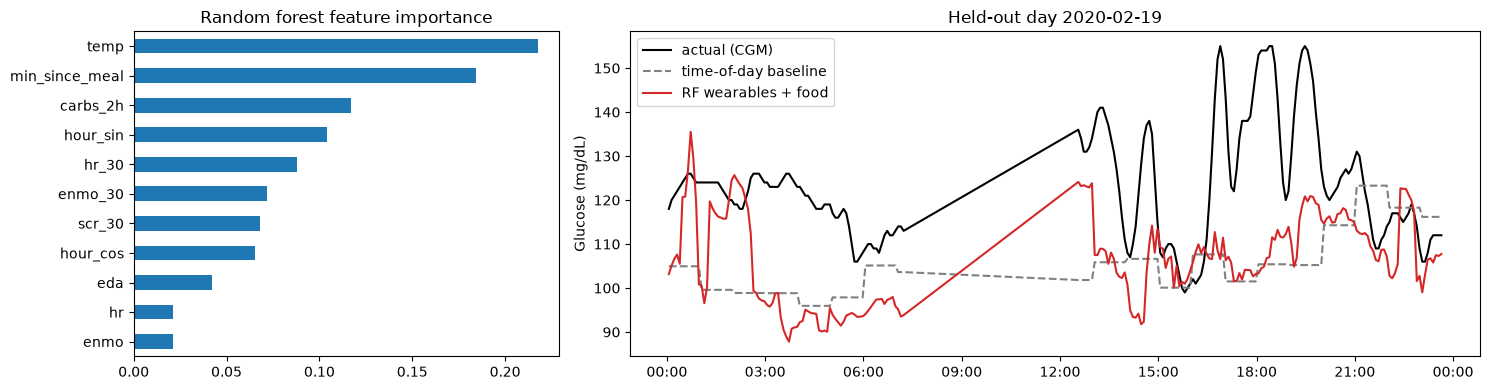

Note: impurity-based importance favours features with many distinct values; treat it as a rough guide.


In [33]:
if SKLEARN and preds:
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=0, n_jobs=-1)
    rf.fit(model_df[WITH_FOOD], model_df["glucose"])
    imp = pd.Series(rf.feature_importances_, index=WITH_FOOD).sort_values()

    fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 2]})
    imp.plot(kind="barh", ax=axes[0], color="tab:blue")
    axes[0].set_title("Random forest feature importance")

    ex = preds[len(preds) // 2]
    axes[1].plot(ex["time"], ex["actual"], color="black", lw=1.5, label="actual (CGM)")
    axes[1].plot(ex["time"], ex["time-of-day mean"], color="gray", ls="--", label="time-of-day baseline")
    axes[1].plot(ex["time"], ex["Random forest (wearables + food log)"], color="tab:red", label="RF wearables + food")
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    axes[1].set_ylabel("Glucose (mg/dL)")
    axes[1].set_title(f"Held-out day {ex['date']}")
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    print("Note: impurity-based importance favours features with many distinct values; treat it as a rough guide.")

## Q13 (added): Across participants, and HbA1c

Everything so far describes **one person**. The real research questions are about differences **between** people: do participants with higher HbA1c have higher variability, bigger meal spikes, lower HRV, or less activity?

`Demographics.csv` holds each participant's HbA1c and gender. This cell collects the summary CSVs saved by every stage for every participant you've processed so far (change `PID` and rerun the notebooks for 002–016), joins them with the demographics, and correlates each metric with HbA1c. With 16 participants, look for consistent patterns rather than p-values.

In [34]:
stage8_summary_path = f"stage8_summary_{PID}.csv"   # saved at the end of this notebook

def collect(pids):
    rows = []
    for p in pids:
        parts = []
        for s in range(2, 9):
            f = f"stage{s}_summary_{p}.csv"
            if os.path.exists(f):
                parts.append(pd.read_csv(f, index_col=0).add_prefix(f"S{s} "))
        if parts:
            row = pd.concat(parts, axis=1)
            row.index = [int(p)]
            rows.append(row)
    return pd.concat(rows) if rows else pd.DataFrame()

all_p = collect([f"{i:03d}" for i in range(1, 17)])
if os.path.exists(DEMO_PATH) and len(all_p):
    demo = pd.read_csv(DEMO_PATH)
    demo = demo.set_index(pd.to_numeric(demo.iloc[:, 0], errors="coerce").astype("Int64"))
    a1c_col = next(c for c in demo.columns if "a1c" in c.lower())
    combined = all_p.join(demo, how="left")
    print(f"Participants with summaries: {len(combined)}")
    if len(combined) >= 5:
        num = combined.apply(pd.to_numeric, errors="coerce")
        corr_a1c = num.drop(columns=[a1c_col]).apply(
            lambda c: stats.spearmanr(c, num[a1c_col], nan_policy="omit")[0] if c.notna().sum() >= 5 else np.nan)
        print("Metrics most related to HbA1c:")
        print(corr_a1c.dropna().sort_values(key=abs, ascending=False).head(15).round(2))
    else:
        print("Process at least 5 participants to look at HbA1c relationships.")
    display(combined.T.head(30))
else:
    print("No summaries or Demographics.csv found yet.")

Participants with summaries: 1
Process at least 5 participants to look at HbA1c relationships.


,1
S8 Movement–HR activity agreement (kappa),0.04
S8 Median glucose change 60 min after exercise bouts,-7.0
S8 Nights detected (movement + HR),7.0
S8 Glucose SD asleep,10.8
S8 Glucose SD awake,16.6
S8 HR–glucose r (all),-0.07
S8 HR–glucose r (5-min changes),-0.01
S8 HR–glucose partial r,0.09
S8 Median HR change after resting meals (bpm),-1.7
S8 Median RMSSD asleep (ms),60.9


---
## Summary

In [35]:
def safe(v, nd=2):
    try:
        return round(float(v), nd)
    except (TypeError, ValueError):
        return np.nan

summary = pd.Series({
    "Movement–HR activity agreement (kappa)": safe(kappa),
    "Median glucose change 60 min after exercise bouts": safe(bout_glu.loc[(bout_glu["type"] == "both") & ~bout_glu["meal_nearby"], "change_60"].median(), 1) if len(bout_glu) else np.nan,
    "Nights detected (movement + HR)": len(nights),
    "Glucose SD asleep": safe(stab.loc["SD", "asleep"], 1),
    "Glucose SD awake": safe(stab.loc["SD", "awake, all"], 1),
    "HR–glucose r (all)": safe(report["all worn data"].get("pearson r")),
    "HR–glucose r (5-min changes)": safe(report["5-min changes"].get("pearson r")),
    "HR–glucose partial r": safe(report["adjusted for movement + time of day"].get("pearson r")),
    "Median HR change after resting meals (bpm)": safe(pp["hr_change"].median(), 1) if len(pp) else np.nan,
    "Median RMSSD asleep (ms)": safe(df.loc[df["asleep2"], "rmssd"].median(), 1),
    "Median RMSSD awake rest (ms)": safe(df.loc[df["state"] == "rest", "rmssd"].median(), 1),
    "Best model MAE (mg/dL)": safe(res_tab["MAE"].min(), 1) if results else np.nan,
    "Time-of-day baseline MAE (mg/dL)": safe(res_tab.loc["time-of-day mean", "MAE"], 1) if results else np.nan,
}, name=PID)
summary.to_frame()

,001
Movement–HR activity agreement (kappa),0.04
Median glucose change 60 min after exercise bouts,-7.00
Nights detected (movement + HR),7.00
Glucose SD asleep,10.80
Glucose SD awake,16.60
HR–glucose r (all),-0.07
HR–glucose r (5-min changes),-0.01
HR–glucose partial r,0.09
Median HR change after resting meals (bpm),-1.70
Median RMSSD asleep (ms),60.90


In [36]:
summary.to_frame().T.rename_axis("participant").to_csv(f"stage8_summary_{PID}.csv")
df.drop(columns=["date"]).round(3).to_csv(f"multisensor_5min_{PID}.csv")
print(f"Saved stage8_summary_{PID}.csv and multisensor_5min_{PID}.csv")

Saved stage8_summary_001.csv and multisensor_5min_001.csv


---
## Going further

Once you're comfortable with this notebook, these directions build real expertise:

1. **Repeat for all 16 participants.** Change `PID` and rerun Stages 1–8, then use Q13 to compare people. Individual differences are where most of the interesting science is.
2. **BVP (raw pulse waveform, 64 Hz).** Compute your own heart rate and HRV from the waveform, add a signal-quality index, and compare with the E4's own HR and IBI values.
3. **Better HRV.** Add frequency-domain HRV (LF/HF power) and night-only HRV per participant.
4. **Glucose prediction.** Instead of estimating glucose from wearables alone, forecast glucose 30–60 minutes ahead using past glucose plus wearables (the classic CGM forecasting problem). Compare with a simple "glucose stays the same" baseline.
5. **Variability metrics.** Implement MAGE (mean amplitude of glycemic excursions) and CONGA, which are common in research papers.
6. **Read the source papers.** The dataset was introduced in Bent et al., *npj Digital Medicine* (2021), "Engineering digital biomarkers of interstitial glucose from noninvasive smartwatches". Comparing your results with theirs is an excellent way to check your understanding.